1. GAMBARAN UMUM DATASET
Total baris      : 58,943
Total kolom      : 8
Kolom            : ['Poli_Tujuan', 'URL', 'Keluhan', 'Jawaban_Dokter', 'len_keluhan', 'len_jawaban', 'word_keluhan', 'word_jawaban']
Jumlah poli unik : 1,422

Null values:
Poli_Tujuan       0
URL               0
Keluhan           0
Jawaban_Dokter    0

Duplikat URL     : 0

2. STATISTIK PANJANG TEKS
       len_keluhan  len_jawaban  word_keluhan  word_jawaban
count      58943.0      58943.0       58943.0       58943.0
mean         340.0       1487.5          53.1         205.2
std          269.9        560.1          38.6          76.6
min            1.0          2.0           1.0           1.0
25%          199.0       1119.0          31.0         155.0
50%          277.0       1388.0          44.0         192.0
75%          408.0       1765.0          64.0         243.0
max        23522.0      10440.0        1327.0        1380.0

3. DISTRIBUSI JUMLAH DATA PER POLI
Poli dengan data terbanyak (top 10):
Poli_Tujuan
ab

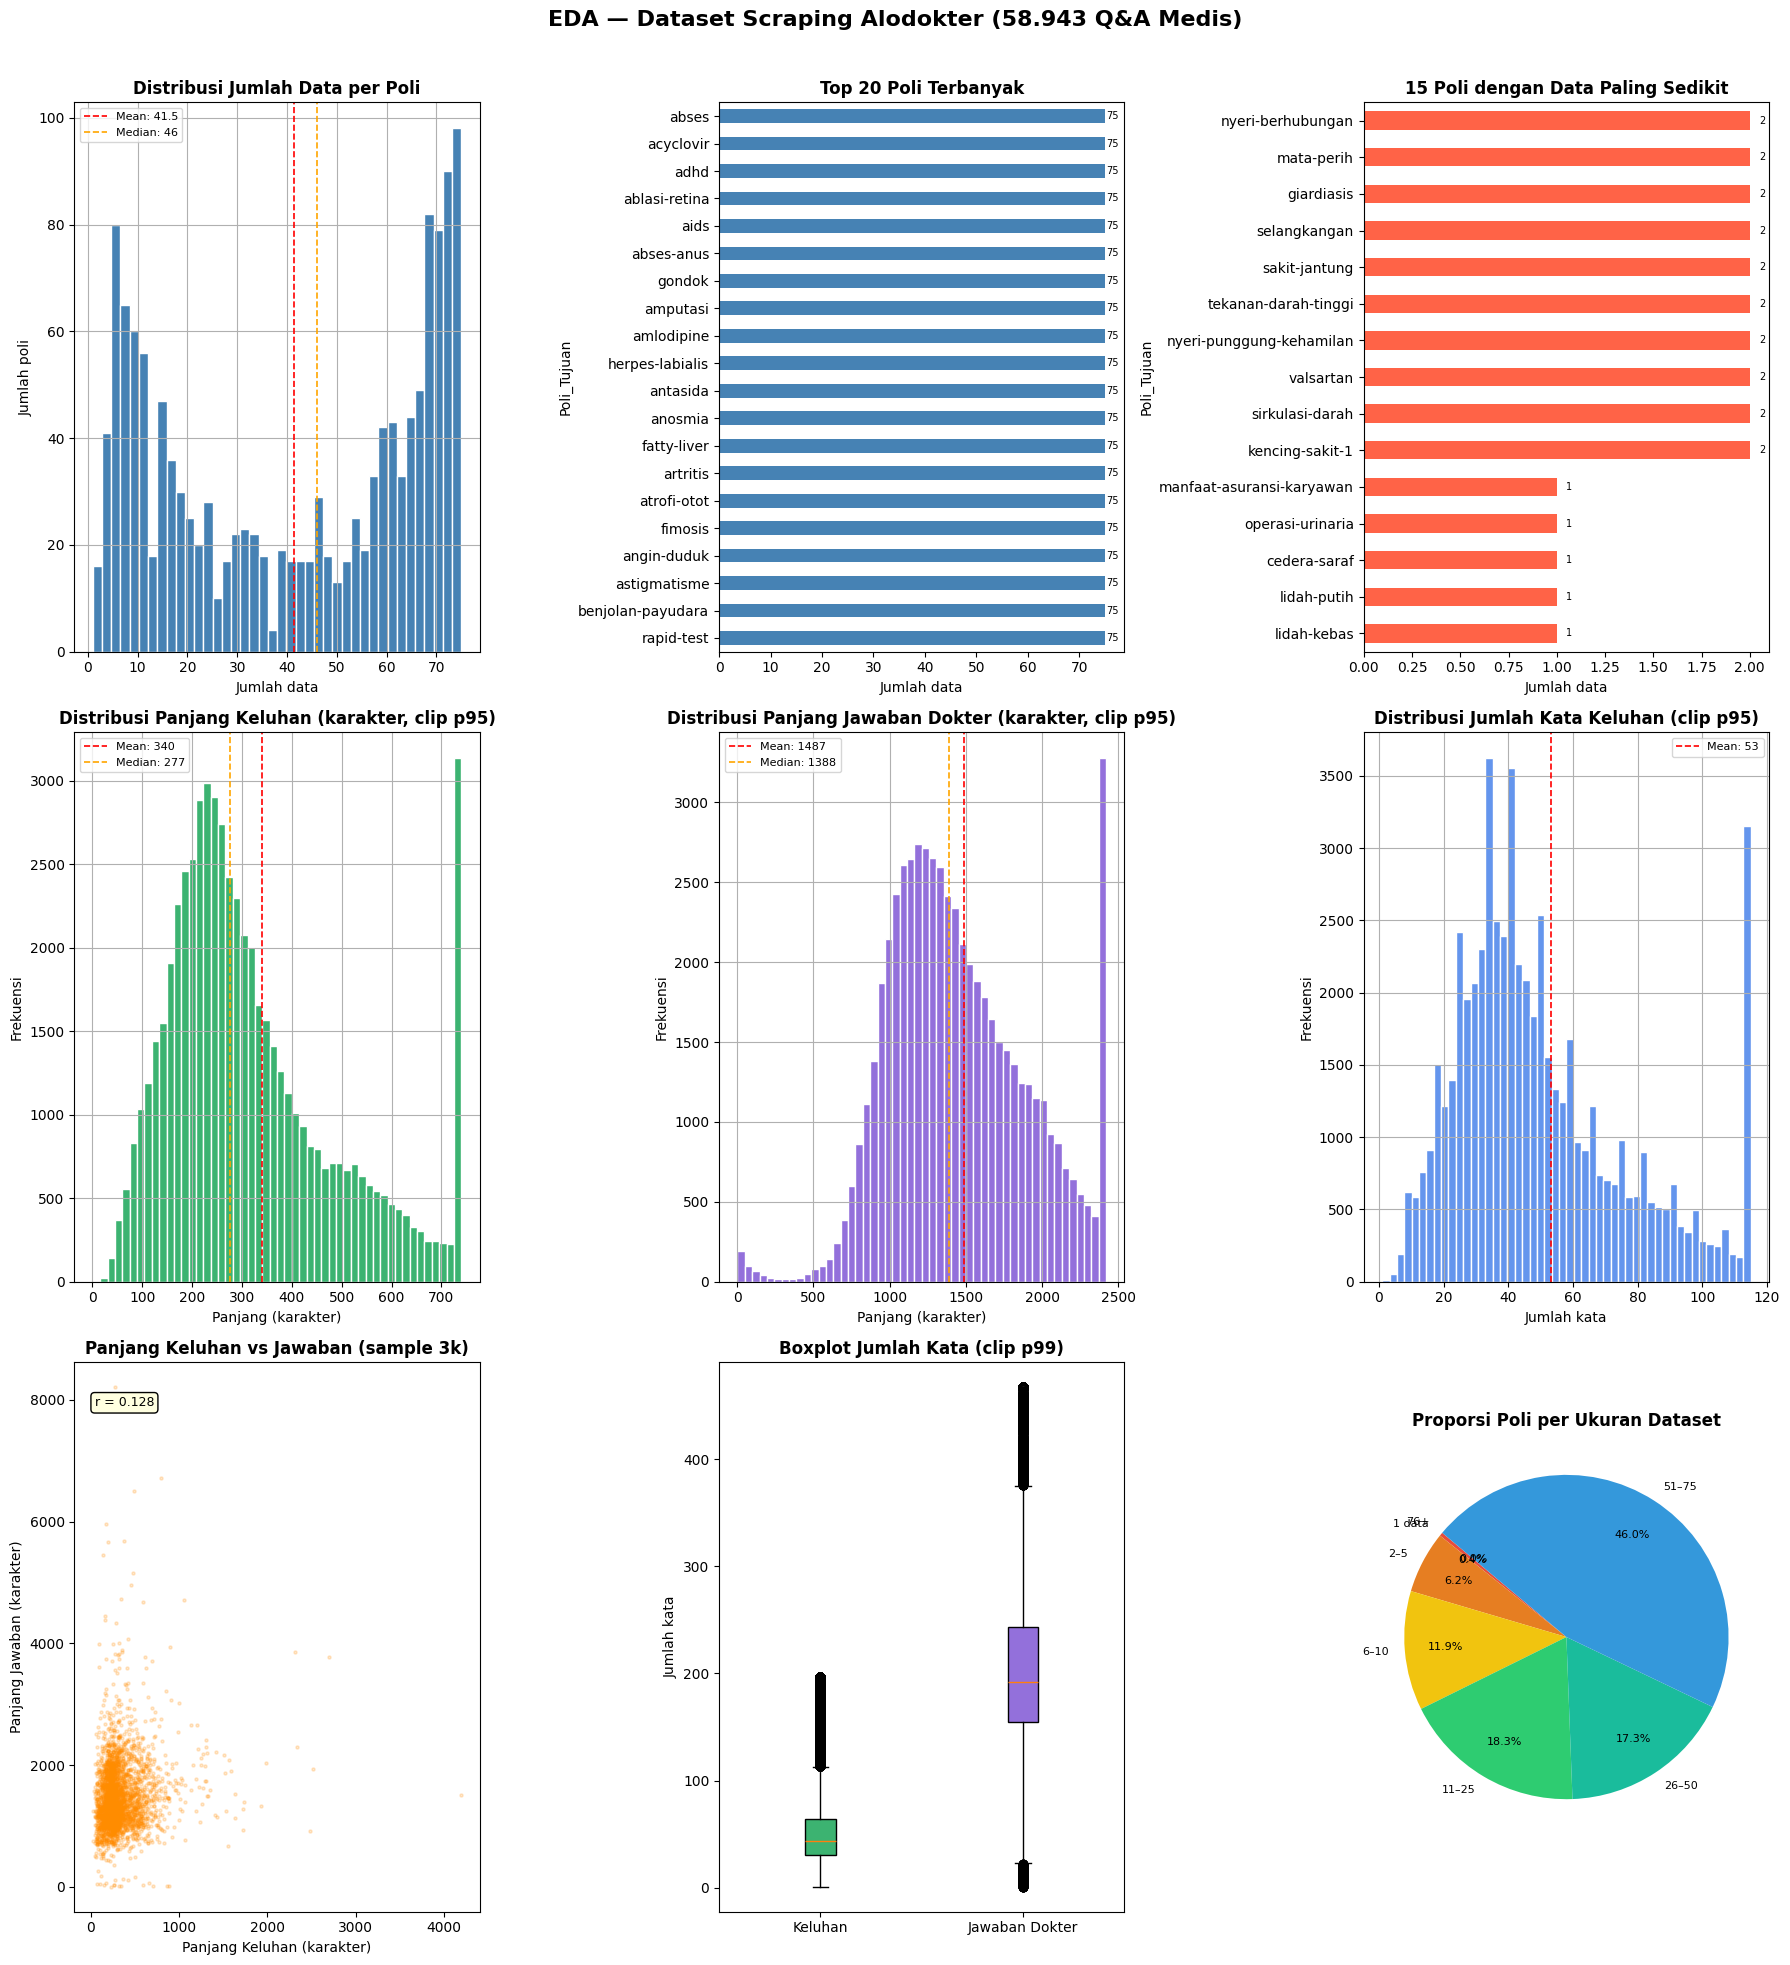


Visualisasi disimpan ke: eda_scraping_alodokter.png

RINGKASAN EDA
Total pasang tanya-jawab : 58,943
Kategori poli unik       : 1,422
Poli dominan (>=50 data) : 667 poli
Poli langka (<=5 data)   : 93 poli

Keluhan  — rata-rata 53 kata (median 44, max 1,327)
Jawaban  — rata-rata 205 kata (median 192, max 1,380)
Korelasi panjang (r)     : 0.128
Null values              : 0 di semua kolom
Duplikat URL             : 0


: 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# LOAD DATA
# ============================================================
df = pd.read_csv(r'C:\Semester 4\FINAL PROJECT\NLP\Dataset\3_dataset_nlp_medis_complete.csv')

# Feature tambahan: panjang teks
df['len_keluhan']  = df['Keluhan'].str.len()
df['len_jawaban']  = df['Jawaban_Dokter'].str.len()
df['word_keluhan'] = df['Keluhan'].str.split().str.len()
df['word_jawaban'] = df['Jawaban_Dokter'].str.split().str.len()

print("=" * 60)
print("1. GAMBARAN UMUM DATASET")
print("=" * 60)
print(f"Total baris      : {len(df):,}")
print(f"Total kolom      : {df.shape[1]}")
print(f"Kolom            : {df.columns.tolist()}")
print(f"Jumlah poli unik : {df['Poli_Tujuan'].nunique():,}")
print(f"\nNull values:")
print(df[['Poli_Tujuan','URL','Keluhan','Jawaban_Dokter']].isnull().sum().to_string())
print(f"\nDuplikat URL     : {df['URL'].duplicated().sum()}")

print("\n" + "=" * 60)
print("2. STATISTIK PANJANG TEKS")
print("=" * 60)
stats_cols = ['len_keluhan','len_jawaban','word_keluhan','word_jawaban']
print(df[stats_cols].describe().round(1).to_string())

print("\n" + "=" * 60)
print("3. DISTRIBUSI JUMLAH DATA PER POLI")
print("=" * 60)
poli_counts = df['Poli_Tujuan'].value_counts()
print(f"Poli dengan data terbanyak (top 10):")
print(poli_counts.head(10).to_string())
print(f"\nPoli dengan data paling sedikit (bottom 10):")
print(poli_counts.tail(10).to_string())
print(f"\nDistribusi bucket jumlah data per poli:")
buckets = pd.cut(poli_counts, bins=[0,1,5,10,25,50,75,100], 
                 labels=['1','2–5','6–10','11–25','26–50','51–75','76–100'])
print(buckets.value_counts().sort_index().to_string())

print("\n" + "=" * 60)
print("4. CONTOH DATA NYATA")
print("=" * 60)
sample = df.sample(3, random_state=42)[['Poli_Tujuan','Keluhan','Jawaban_Dokter']]
for i, (_, row) in enumerate(sample.iterrows(), 1):
    print(f"\n--- Contoh {i} | Poli: {row['Poli_Tujuan']} ---")
    print(f"Keluhan  : {row['Keluhan'][:200]}...")
    print(f"Jawaban  : {row['Jawaban_Dokter'][:200]}...")

# ============================================================
# VISUALISASI
# ============================================================
fig = plt.figure(figsize=(18, 20))
fig.suptitle('EDA — Dataset Scraping Alodokter (58.943 Q&A Medis)',
             fontsize=16, fontweight='bold', y=0.98)

# ── Plot 1: Distribusi jumlah data per poli (histogram) ──
ax1 = fig.add_subplot(3, 3, 1)
poli_counts.hist(bins=40, ax=ax1, color='steelblue', edgecolor='white')
ax1.set_title('Distribusi Jumlah Data per Poli', fontweight='bold')
ax1.set_xlabel('Jumlah data')
ax1.set_ylabel('Jumlah poli')
ax1.axvline(poli_counts.mean(), color='red', linestyle='--', linewidth=1.2,
            label=f'Mean: {poli_counts.mean():.1f}')
ax1.axvline(poli_counts.median(), color='orange', linestyle='--', linewidth=1.2,
            label=f'Median: {poli_counts.median():.0f}')
ax1.legend(fontsize=8)

# ── Plot 2: Top 20 poli ──
ax2 = fig.add_subplot(3, 3, 2)
top20 = poli_counts.head(20)
top20.plot(kind='barh', ax=ax2, color='steelblue')
ax2.set_title('Top 20 Poli Terbanyak', fontweight='bold')
ax2.set_xlabel('Jumlah data')
ax2.invert_yaxis()
for i, v in enumerate(top20.values):
    ax2.text(v + 0.3, i, str(v), va='center', fontsize=7)

# ── Plot 3: Bottom 15 poli ──
ax3 = fig.add_subplot(3, 3, 3)
bot15 = poli_counts.tail(15).sort_values(ascending=True)
bot15.plot(kind='barh', ax=ax3, color='tomato')
ax3.set_title('15 Poli dengan Data Paling Sedikit', fontweight='bold')
ax3.set_xlabel('Jumlah data')
for i, v in enumerate(bot15.values):
    ax3.text(v + 0.05, i, str(v), va='center', fontsize=7)

# ── Plot 4: Distribusi panjang Keluhan (karakter) ──
ax4 = fig.add_subplot(3, 3, 4)
q95_k = df['len_keluhan'].quantile(0.95)
df['len_keluhan'].clip(upper=q95_k).hist(bins=50, ax=ax4,
                                          color='mediumseagreen', edgecolor='white')
ax4.set_title('Distribusi Panjang Keluhan (karakter, clip p95)', fontweight='bold')
ax4.set_xlabel('Panjang (karakter)')
ax4.set_ylabel('Frekuensi')
ax4.axvline(df['len_keluhan'].mean(), color='red', linestyle='--', linewidth=1.2,
            label=f"Mean: {df['len_keluhan'].mean():.0f}")
ax4.axvline(df['len_keluhan'].median(), color='orange', linestyle='--', linewidth=1.2,
            label=f"Median: {df['len_keluhan'].median():.0f}")
ax4.legend(fontsize=8)

# ── Plot 5: Distribusi panjang Jawaban_Dokter (karakter) ──
ax5 = fig.add_subplot(3, 3, 5)
q95_j = df['len_jawaban'].quantile(0.95)
df['len_jawaban'].clip(upper=q95_j).hist(bins=50, ax=ax5,
                                          color='mediumpurple', edgecolor='white')
ax5.set_title('Distribusi Panjang Jawaban Dokter (karakter, clip p95)', fontweight='bold')
ax5.set_xlabel('Panjang (karakter)')
ax5.set_ylabel('Frekuensi')
ax5.axvline(df['len_jawaban'].mean(), color='red', linestyle='--', linewidth=1.2,
            label=f"Mean: {df['len_jawaban'].mean():.0f}")
ax5.axvline(df['len_jawaban'].median(), color='orange', linestyle='--', linewidth=1.2,
            label=f"Median: {df['len_jawaban'].median():.0f}")
ax5.legend(fontsize=8)

# ── Plot 6: Distribusi jumlah kata Keluhan ──
ax6 = fig.add_subplot(3, 3, 6)
q95_wk = df['word_keluhan'].quantile(0.95)
df['word_keluhan'].clip(upper=q95_wk).hist(bins=50, ax=ax6,
                                             color='cornflowerblue', edgecolor='white')
ax6.set_title('Distribusi Jumlah Kata Keluhan (clip p95)', fontweight='bold')
ax6.set_xlabel('Jumlah kata')
ax6.set_ylabel('Frekuensi')
ax6.axvline(df['word_keluhan'].mean(), color='red', linestyle='--', linewidth=1.2,
            label=f"Mean: {df['word_keluhan'].mean():.0f}")
ax6.legend(fontsize=8)

# ── Plot 7: Scatter panjang Keluhan vs Jawaban ──
ax7 = fig.add_subplot(3, 3, 7)
sample_scatter = df.sample(3000, random_state=42)
ax7.scatter(sample_scatter['len_keluhan'], sample_scatter['len_jawaban'],
            alpha=0.2, s=5, color='darkorange')
ax7.set_title('Panjang Keluhan vs Jawaban (sample 3k)', fontweight='bold')
ax7.set_xlabel('Panjang Keluhan (karakter)')
ax7.set_ylabel('Panjang Jawaban (karakter)')
corr = df['len_keluhan'].corr(df['len_jawaban'])
ax7.text(0.05, 0.92, f'r = {corr:.3f}', transform=ax7.transAxes,
         fontsize=9, color='black',
         bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow'))

# ── Plot 8: Boxplot perbandingan panjang teks ──
ax8 = fig.add_subplot(3, 3, 8)
data_box = [
    df['word_keluhan'].clip(upper=df['word_keluhan'].quantile(0.99)).values,
    df['word_jawaban'].clip(upper=df['word_jawaban'].quantile(0.99)).values,
]
bp = ax8.boxplot(data_box, labels=['Keluhan', 'Jawaban Dokter'],
                  patch_artist=True, notch=False)
bp['boxes'][0].set_facecolor('mediumseagreen')
bp['boxes'][1].set_facecolor('mediumpurple')
ax8.set_title('Boxplot Jumlah Kata (clip p99)', fontweight='bold')
ax8.set_ylabel('Jumlah kata')
ax8.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

# ── Plot 9: Pie chart bucket ukuran poli ──
ax9 = fig.add_subplot(3, 3, 9)
bucket_labels  = ['1 data', '2–5', '6–10', '11–25', '26–50', '51–75', '76+']
bucket_counts  = pd.cut(poli_counts,
                         bins=[0,1,5,10,25,50,75,poli_counts.max()+1],
                         labels=bucket_labels).value_counts().sort_index()
colors_pie = ['#e74c3c','#e67e22','#f1c40f','#2ecc71','#1abc9c','#3498db','#9b59b6']
wedges, texts, autotexts = ax9.pie(
    bucket_counts, labels=bucket_labels, autopct='%1.1f%%',
    colors=colors_pie, startangle=140, pctdistance=0.75,
    textprops={'fontsize': 8})
ax9.set_title('Proporsi Poli per Ukuran Dataset', fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('eda_scraping_alodokter.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nVisualisasi disimpan ke: eda_scraping_alodokter.png")

# ============================================================
# RINGKASAN AKHIR
# ============================================================
print("\n" + "=" * 60)
print("RINGKASAN EDA")
print("=" * 60)
print(f"Total pasang tanya-jawab : {len(df):,}")
print(f"Kategori poli unik       : {df['Poli_Tujuan'].nunique():,}")
print(f"Poli dominan (>=50 data) : {(poli_counts >= 50).sum():,} poli")
print(f"Poli langka (<=5 data)   : {(poli_counts <= 5).sum():,} poli")
print(f"\nKeluhan  — rata-rata {df['word_keluhan'].mean():.0f} kata "
      f"(median {df['word_keluhan'].median():.0f}, max {df['word_keluhan'].max():,})")
print(f"Jawaban  — rata-rata {df['word_jawaban'].mean():.0f} kata "
      f"(median {df['word_jawaban'].median():.0f}, max {df['word_jawaban'].max():,})")
print(f"Korelasi panjang (r)     : {corr:.3f}")
print(f"Null values              : 0 di semua kolom")
print(f"Duplikat URL             : {df['URL'].duplicated().sum()}")